# Integrated Syntactic–Semantic Analysis: Keyword Extraction and Sentiment

**Authors:** Steve and Spencer
**Topic 4:** Integrated Analysis (coding task)

## Goal

1. Use **dependency parsing** (syntax) to pull out keywords and phrases from real airline tweets.
2. Score the **sentiment** (semantics) of those phrases.
3. Test whether combining the two beats scoring whole tweets on their own, by checking both against the human sentiment labels in the dataset.

## Data

`Tweets.csv` holds about 14,600 tweets sent to six US airlines in February 2015. Each tweet has a human-assigned `airline_sentiment` (positive, neutral, negative), the `airline`, and for negative tweets a `negativereason` (for example *Lost Luggage* or *Late Flight*). We parse the **raw tweet text**, because the grammar, stopwords and negation words that dependency parsing relies on would be lost in a pre-tokenised, lemmatised version.

## Approach

| Step | Layer | Tool |
|---|---|---|
| Clean tweets lightly (mentions, URLs, HTML entities) and drop duplicates | Preprocessing | `re`, pandas |
| Parse each tweet into a dependency tree | Syntax | spaCy `en_core_web_sm` |
| Extract aspect + opinion pairs from specific grammatical relations | Syntax | `amod`, `nsubj`+`acomp`/`attr`, `dobj`, `neg`, `advmod`, `conj` |
| Group raw nouns into airline aspects (luggage, crew, delays, ...) | Syntax + domain knowledge | keyword map |
| Score the opinion word, then adjust for negation and intensifiers | Semantics | VADER lexicon + a few airline terms |
| Aggregate by aspect and by airline | Both | pandas + matplotlib |
| Compare phrase-level and tweet-level sentiment with the human labels | Evaluation | pandas |

## 1. Setup

Run the next cell once if the libraries are not installed yet.

In [1]:
# Uncomment and run once if needed
# !pip install spacy vaderSentiment pandas matplotlib numpy
# !python -m spacy download en_core_web_sm

In [2]:
import html
import os
import re
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import spacy
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

nlp = spacy.load("en_core_web_sm")
vader = SentimentIntensityAnalyzer()
pd.set_option("display.max_colwidth", 90)
print("spaCy", spacy.__version__, "| model:", nlp.meta["name"])

spaCy 3.8.18 | model: core_web_sm


## 2. Load and clean the tweets

Cleaning is deliberately light. We remove things that are not language (the `@airline` mention at the start, URLs, HTML entities such as `&amp;`, and the `#` symbol) but keep punctuation, stopwords and negations, since the parser needs them.

Set `SAMPLE_SIZE` to a number such as `2000` for a quick test run; leave it as `None` to use every tweet.

In [3]:
DATA_PATH = "Tweets.csv"
PREPROCESSED_PATH = "tweets_preprocessed__1_.csv"   # only used for the optional cross-check below
SAMPLE_SIZE = None        # e.g. 2000 for a quick test run
RANDOM_STATE = 42

URL_RE = re.compile(r"https?://\S+|www\.\S+")
MENTION_RE = re.compile(r"@\w+")

def clean_tweet(text):
    text = html.unescape(text)
    text = URL_RE.sub(" ", text)
    text = MENTION_RE.sub(" ", text)
    text = text.replace("#", "")
    return re.sub(r"\s+", " ", text).strip()

raw = pd.read_csv(DATA_PATH)
tweets = raw[["tweet_id", "airline", "airline_sentiment", "negativereason", "text"]].copy()
tweets["clean_text"] = tweets["text"].map(clean_tweet)

n_raw = len(tweets)
tweets = tweets[tweets["clean_text"].str.len() >= 3]
n_short = n_raw - len(tweets)
tweets = tweets.drop_duplicates(subset="clean_text")
n_dupes = n_raw - n_short - len(tweets)
tweets = tweets.reset_index(drop=True)

if SAMPLE_SIZE:
    tweets = tweets.sample(SAMPLE_SIZE, random_state=RANDOM_STATE).reset_index(drop=True)

print(f"raw tweets: {n_raw} | too short after cleaning: {n_short} | duplicates removed: {n_dupes}")
print(f"tweets used: {len(tweets)}")
print()
print(tweets["airline_sentiment"].value_counts(normalize=True).round(3).to_string())
tweets[["text", "clean_text"]].head(5)

raw tweets: 14640 | too short after cleaning: 0 | duplicates removed: 346
tweets used: 14294

airline_sentiment
negative    0.635
neutral     0.209
positive    0.157


,text,clean_text
0,@VirginAmerica What @dhepburn said.,What said.
1,@VirginAmerica plus you've added commercials to the experience... tacky.,plus you've added commercials to the experience... tacky.
2,@VirginAmerica I didn't today... Must mean I need to take another trip!,I didn't today... Must mean I need to take another trip!
3,"@VirginAmerica it's really aggressive to blast obnoxious ""entertainment"" in your guest...","it's really aggressive to blast obnoxious ""entertainment"" in your guests' faces & they..."
4,@VirginAmerica and it's a really big bad thing about it,and it's a really big bad thing about it


### Optional cross-check against the preprocessed file

`tweets_preprocessed__1_.csv` contains the same tweets after tokenising, stopword removal, lemmatising and stemming. We do not parse it, but we can confirm both files describe the same data and that the labels agree.

In [4]:
if os.path.exists(PREPROCESSED_PATH):
    pre = pd.read_csv(PREPROCESSED_PATH, usecols=["tweet_id", "airline_sentiment", "clean_text"])
    pre = pre.drop_duplicates("tweet_id")
    merged = tweets.merge(pre, on="tweet_id", how="left", suffixes=("", "_pre"))
    found = merged["airline_sentiment_pre"].notna()
    print(f"tweets also present in the preprocessed file: {found.sum()} of {len(merged)} ({found.mean():.1%})")
    print(f"sentiment labels that agree between the two files: {(merged.loc[found, 'airline_sentiment'] == merged.loc[found, 'airline_sentiment_pre']).mean():.1%}")
    print()
    print("Example of what preprocessing removes (why we parse the raw text instead):")
    ex = merged[found].head(3)
    for _, r in ex.iterrows():
        print("  raw :", r["text"])
        print("  prep:", r["clean_text_pre"])
else:
    print("Preprocessed file not found, skipping cross-check.")

tweets also present in the preprocessed file: 14270 of 14294 (99.8%)
sentiment labels that agree between the two files: 100.0%

Example of what preprocessing removes (why we parse the raw text instead):
  raw : @VirginAmerica What @dhepburn said.
  prep: what said.
  raw : @VirginAmerica plus you've added commercials to the experience... tacky.
  prep: plus you've added commercials to the experience... tacky.
  raw : @VirginAmerica I didn't today... Must mean I need to take another trip!
  prep: i didn't today... must mean i need to take another trip!


## 3. Look at a dependency parse

Before extracting anything, it helps to see the tree for one sentence. Each token has a **dependency label** (`dep_`) and a **head** that it attaches to. These relations are what we will use as extraction rules.

In [5]:
doc = nlp("The crew was not friendly and the flight was delayed.")
pd.DataFrame(
    [(t.i, t.text, t.pos_, t.dep_, t.head.text) for t in doc],
    columns=["i", "token", "pos", "dep", "head"],
)

,i,token,pos,dep,head
0,0,The,DET,det,crew
1,1,crew,NOUN,nsubj,was
2,2,was,AUX,ROOT,was
3,3,not,PART,neg,was
4,4,friendly,ADJ,acomp,was
5,5,and,CCONJ,cc,was
6,6,the,DET,det,flight
7,7,flight,NOUN,nsubjpass,delayed
8,8,was,AUX,auxpass,delayed
9,9,delayed,VERB,conj,was


In [6]:
from spacy import displacy
displacy.render(nlp("The crew was not friendly."), style="dep", jupyter=True, options={"distance": 90})

## 4. Syntactic extraction: aspects, opinions and phrases

We look for four grammatical patterns. Each one yields an **aspect** (the thing being talked about) and an **opinion** (what is said about it).

| Pattern | Dependency rule | Example |
|---|---|---|
| Adjective modifier | adjective with `amod` attached to a noun | *rude crew* |
| Copular predicate | noun `nsubj` of a verb that has an `acomp` or `attr` child | *flight is great* |
| Verb + object | opinion verb with a `dobj` noun | *lost my bag* |
| Coordination | `conj` words joined to an opinion word | *friendly and helpful* |

We also record **negation** (a `neg` child on the opinion word or on the verb it hangs from) and **intensifiers** (an `advmod` child such as *very* or *really*).

In [7]:
NOUNS = {"NOUN", "PROPN"}
INTENSIFIERS = {"very", "really", "extremely", "so", "incredibly", "absolutely", "super",
                "totally", "completely", "utterly"}

def is_negated(opinion_tok, governor=None):
    """Negation can sit on the opinion word itself or on the verb it attaches to."""
    if any(c.dep_ == "neg" for c in opinion_tok.children):
        return True
    if governor is not None and any(c.dep_ == "neg" for c in governor.children):
        return True
    return False

def intensity(opinion_tok):
    return 1.3 if any(c.dep_ == "advmod" and c.lower_ in INTENSIFIERS for c in opinion_tok.children) else 1.0

def aspect_text(noun_tok):
    """Use the noun's lemma, plus a leading compound noun if there is one (customer service)."""
    comps = [c.lemma_.lower() for c in noun_tok.children if c.dep_ == "compound"]
    return " ".join(comps + [noun_tok.lemma_.lower()])

def extract_pairs(doc):
    pairs, seen = [], set()

    def add(aspect_tok, opinion_tok, rule, governor=None):
        key = (aspect_tok.i, opinion_tok.i)
        if key in seen:
            return
        seen.add(key)
        pairs.append({
            "aspect": aspect_text(aspect_tok),
            "opinion": opinion_tok.lower_,
            "negated": is_negated(opinion_tok, governor),
            "boost": intensity(opinion_tok),
            "rule": rule,
        })

    for tok in doc:
        # 1) amod: "rude crew"
        if tok.dep_ == "amod" and tok.head.pos_ in NOUNS:
            add(tok.head, tok, "amod")
            for conj in tok.conjuncts:
                add(tok.head, conj, "amod+conj")

        # 2) copular: "the crew is (not) friendly"
        if tok.dep_ == "nsubj" and tok.pos_ in NOUNS:
            gov = tok.head
            for child in gov.children:
                if child.dep_ in ("acomp", "attr"):
                    add(tok, child, "nsubj+acomp", governor=gov)
                    for conj in child.conjuncts:
                        add(tok, conj, "nsubj+acomp+conj", governor=gov)

        # 3) verb + direct object: "love the crew", "lost my bag"
        if tok.dep_ == "dobj" and tok.pos_ in NOUNS:
            verb = tok.head
            if verb.pos_ == "VERB":
                add(tok, verb, "verb+dobj")

    return pairs

for p in extract_pairs(nlp("The crew was not friendly and the flight was delayed.")):
    print(p)

{'aspect': 'crew', 'opinion': 'friendly', 'negated': True, 'boost': 1.0, 'rule': 'nsubj+acomp'}


### Keyword and phrase extraction

Alongside the aspect/opinion pairs we pull out **noun phrases** (`noun_chunks`), dropping determiners, pronouns and stopwords. These are the keywords we count.

In [8]:
def keyword_phrases(doc):
    phrases = []
    for chunk in doc.noun_chunks:
        toks = [t for t in chunk if t.pos_ not in ("DET", "PRON") and not t.is_stop]
        if toks:
            phrases.append(" ".join(t.lemma_.lower() for t in toks))
    return phrases

for text in tweets["clean_text"].head(4):
    print(text)
    print("  ->", keyword_phrases(nlp(text)))

What said.
  -> []
plus you've added commercials to the experience... tacky.
  -> ['commercial', 'experience']
I didn't today... Must mean I need to take another trip!
  -> ['trip']
it's really aggressive to blast obnoxious "entertainment" in your guests' faces & they have little recourse
  -> ['obnoxious " entertainment', "guest ' face", 'little recourse']


## 5. Semantic step: sentiment of each opinion

The score for an opinion word comes from the VADER lexicon. VADER is a general-purpose lexicon and misses several words that matter in airline complaints (*delays*, *canceled*, *stranded*, *overbooked*), so we add a small set of domain terms first. The syntax-derived flags then adjust the score:

- **Negated:** flip the sign and shrink it a little (*not good* is mildly negative, not as strong as *terrible*).
- **Intensified:** multiply by 1.3 (*really impressive*).

Result is a value in roughly [-1, 1].

In [9]:
DOMAIN_LEXICON = {
    "delayed": -1.8, "delay": -1.6, "delays": -1.6,
    "canceled": -2.0, "cancelled": -2.0, "cancellation": -1.6, "cancellations": -1.6,
    "flightled": -1.8,        # artefact of "Cancelled Flight" in many tweets
    "stranded": -2.0, "overbooked": -1.8, "late": -1.2, "unhelpful": -1.8, "smooth": 1.5,
}

before = {w: vader.polarity_scores(w)["compound"] for w in DOMAIN_LEXICON}
vader.lexicon.update(DOMAIN_LEXICON)
after = {w: vader.polarity_scores(w)["compound"] for w in DOMAIN_LEXICON}
pd.DataFrame({"vader_before": before, "with_domain_terms": after}).round(3).T

,delayed,delay,delays,canceled,cancelled,cancellation,cancellations,flightled,stranded,overbooked,late,unhelpful,smooth
vader_before,-0.226,-0.318,0.000,0.000,-0.250,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
with_domain_terms,-0.422,-0.382,-0.382,-0.459,-0.459,-0.382,-0.382,-0.422,-0.459,-0.422,-0.296,-0.422,0.361


In [10]:
NEG_FACTOR = -0.75

def opinion_score(opinion, negated, boost):
    score = vader.polarity_scores(opinion)["compound"]
    score *= boost
    if negated:
        score *= NEG_FACTOR
    return max(-1.0, min(1.0, score))

def label(score, thr=0.05):
    return "positive" if score > thr else "negative" if score < -thr else "neutral"

for args in [("friendly", False, 1.0), ("friendly", True, 1.0), ("helpful", False, 1.3), ("rude", False, 1.0), ("delayed", False, 1.0)]:
    print(args, "->", round(opinion_score(*args), 3))

('friendly', False, 1.0) -> 0.494
('friendly', True, 1.0) -> -0.37
('helpful', False, 1.3) -> 0.548
('rude', False, 1.0) -> -0.459
('delayed', False, 1.0) -> -0.421


## 6. Grouping raw nouns into airline aspects

The parser returns whatever noun the opinion is attached to (*bag*, *luggage*, *baggage*, *suitcase*). To report on airline topics we map those nouns to a small set of aspect groups. Matching starts from the head noun of the phrase (the last word, so *flight attendant* maps through *attendant*). Anything not in the map goes to `other`, and the raw noun is always kept so the mapping can be audited.

In [11]:
ASPECT_GROUPS = {
    "flight & aircraft": ["flight", "flighted", "flightr", "flightling", "flt", "plane", "aircraft",
                          "trip", "connection", "departure", "landing", "takeoff", "route"],
    "delays & timing": ["delay", "time", "hour", "hrs", "hr", "min", "minute", "wait", "weather",
                        "schedule", "layover"],
    "customer service": ["service", "customerservice", "customer", "support", "agent", "rep",
                         "representative", "help", "response", "reply", "communication", "call",
                         "email", "care", "apology", "answer", "info", "information", "update",
                         "message", "phone"],
    "crew & staff": ["crew", "pilot", "attendant", "staff", "employee", "team", "guy", "steward",
                     "captain", "member", "worker"],
    "baggage": ["bag", "baggage", "luggage", "suitcase", "clothe", "item", "carryon"],
    "seat & cabin": ["seat", "seating", "class", "legroom", "cabin", "upgrade", "room"],
    "booking & website": ["ticket", "reservation", "booking", "website", "app", "site", "system",
                          "checkin", "online", "pass", "card", "itinerary"],
    "refunds & fees": ["refund", "fee", "fare", "money", "price", "rate", "charge", "voucher",
                       "compensation", "mile", "deal", "credit"],
    "airport & boarding": ["gate", "boarding", "airport", "terminal", "line", "security", "tsa"],
    "in-flight amenities": ["wifi", "tv", "food", "drink", "snack", "video", "entertainment", "movie"],
    "airline overall": ["airline", "airlines", "company", "jetblue", "united", "aa", "sky", "air",
                        "southwest", "delta", "business"],
}
LEMMA_TO_GROUP = {w: g for g, words in ASPECT_GROUPS.items() for w in words}

def aspect_group(aspect):
    for tok in reversed(aspect.split()):
        if tok in LEMMA_TO_GROUP:
            return LEMMA_TO_GROUP[tok]
    return "other"

for a in ["flight attendant", "customer service", "wait time", "bag", "gate agent", "thing"]:
    print(f"{a:18s} -> {aspect_group(a)}")

flight attendant   -> crew & staff


customer service   -> customer service
wait time          -> delays & timing
bag                -> baggage
gate agent         -> customer service
thing              -> other


## 7. Run the pipeline on all tweets

`nlp.pipe` parses the tweets in batches, which is much faster than calling `nlp()` once per tweet. For each tweet we keep:

- every aspect/opinion pair with its phrase score,
- the whole-tweet VADER score (the baseline we want to beat),
- the keyword phrases.

A pair counts as **opinionated** if its score is outside the neutral band (|score| > 0.05). Neutral verbs such as *have* or *get* also match the verb + object rule, and they would otherwise dilute every average.

In [12]:
OPINION_THR = 0.05
pair_rows, tweet_rows = [], []

texts = tweets["clean_text"].tolist()
for i, doc in enumerate(nlp.pipe(texts, batch_size=256, disable=["ner"])):
    meta = tweets.iloc[i]
    sentence_score = vader.polarity_scores(meta["clean_text"])["compound"]   # whole-tweet baseline
    scores = []
    for p in extract_pairs(doc):
        s = opinion_score(p["opinion"], p["negated"], p["boost"])
        scores.append(s)
        pair_rows.append({
            "tweet": i,
            "airline": meta["airline"],
            "aspect_raw": p["aspect"],
            "aspect": aspect_group(p["aspect"]),
            "opinion": ("not " if p["negated"] else "") + p["opinion"],
            "rule": p["rule"],
            "phrase_score": round(s, 3),
            "phrase_label": label(s),
            "opinionated": abs(s) > OPINION_THR,
        })
    opinionated = [s for s in scores if abs(s) > OPINION_THR]
    tweet_rows.append({
        "tweet": i,
        "airline": meta["airline"],
        "human_label": meta["airline_sentiment"],
        "negativereason": meta["negativereason"],
        "sentence_score": sentence_score,
        "n_pairs": len(scores),
        "n_opinionated": len(opinionated),
        "phrase_mean": float(np.mean(opinionated)) if opinionated else np.nan,
        "keywords": keyword_phrases(doc),
    })

df = pd.DataFrame(pair_rows)
tw = pd.DataFrame(tweet_rows)
op = df[df["opinionated"]]
print(f"{len(tw)} tweets parsed | {len(df)} aspect/opinion pairs | {len(op)} opinionated pairs")
print(f"tweets with at least one opinionated pair: {(tw['n_opinionated'] > 0).mean():.1%}")
df.head(10)

14294 tweets parsed | 21619 aspect/opinion pairs | 5983 opinionated pairs
tweets with at least one opinionated pair: 32.7%


,tweet,airline,aspect_raw,aspect,opinion,rule,phrase_score,phrase_label,opinionated
0,1,Virgin America,commercial,other,added,verb+dobj,0.000,neutral,False
1,2,Virgin America,trip,flight & aircraft,take,verb+dobj,0.000,neutral,False
2,3,Virgin America,entertainment,in-flight amenities,obnoxious,amod,-0.459,negative,True
3,3,Virgin America,entertainment,in-flight amenities,blast,verb+dobj,0.000,neutral,False
4,3,Virgin America,recourse,other,little,amod,0.000,neutral,False
5,3,Virgin America,recourse,other,have,verb+dobj,0.000,neutral,False
6,4,Virgin America,thing,other,big,amod,0.000,neutral,False
7,4,Virgin America,thing,other,bad,amod,-0.542,negative,True
8,5,Virgin America,playing,other,not have,verb+dobj,-0.000,neutral,False
9,5,Virgin America,thing,other,only,amod,0.000,neutral,False


Which grammatical rules produce the pairs, and how much of the vocabulary ended up in `other`:

In [13]:
print(op["rule"].value_counts().to_string())
print()
print(f"opinionated pairs mapped to a named aspect: {(op['aspect'] != 'other').mean():.1%}")
print()
print("Most frequent raw nouns that fell into 'other':")
print(op.loc[op["aspect"] == "other", "aspect_raw"].value_counts().head(15).to_string())

rule
amod                3301
verb+dobj           1934
nsubj+acomp          693
nsubj+acomp+conj      29
amod+conj             26

opinionated pairs mapped to a named aspect: 58.9%

Most frequent raw nouns that fell into 'other':
aspect_raw
experience    106
day            66
job            45
thing          38
work           36
people         35
passenger      35
way            34
luck           21
thank          21
one            16
issue          15
problem        15
friend         13
option         12


## 8. Results

### 8.1 Sentiment per aspect

Averaging the opinionated phrase scores by aspect gives the kind of feature-level view an airline would want from social media.

In [14]:
agg = (op[op["aspect"] != "other"].groupby("aspect")
         .agg(mentions=("phrase_score", "size"),
              mean_sentiment=("phrase_score", "mean"),
              share_negative=("phrase_label", lambda s: (s == "negative").mean()))
         .sort_values("mean_sentiment"))
agg["mean_sentiment"] = agg["mean_sentiment"].round(3)
agg["share_negative"] = agg["share_negative"].round(3)
agg

,mentions,mean_sentiment,share_negative
aspect,,,
baggage,199,-0.244,0.859
flight & aircraft,1285,-0.239,0.831
delays & timing,235,-0.177,0.702
airport & boarding,48,-0.125,0.688
airline overall,235,-0.072,0.570
booking & website,120,-0.044,0.575
customer service,802,-0.027,0.537
seat & cabin,109,0.021,0.523
refunds & fees,120,0.039,0.517


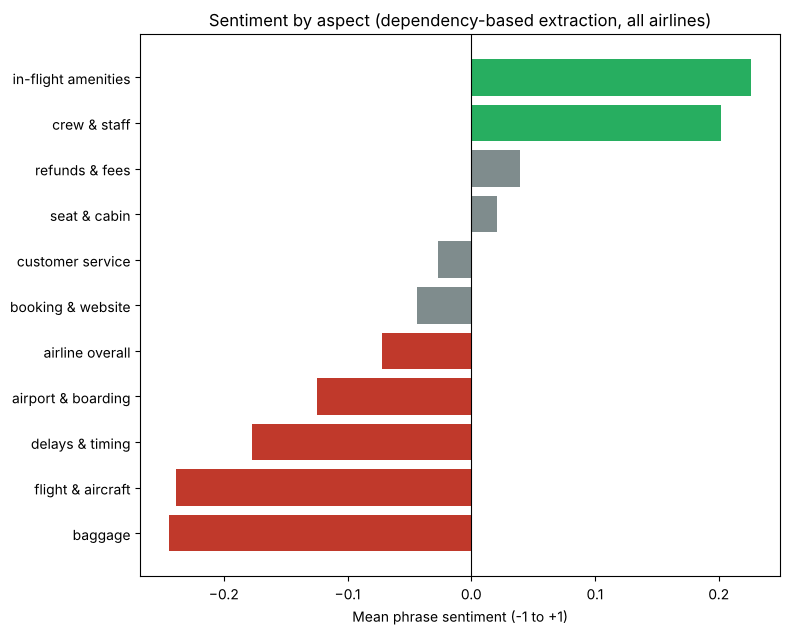

In [15]:
plot_df = agg[agg["mentions"] >= 20]
colors = ["#c0392b" if v < -0.05 else "#27ae60" if v > 0.05 else "#7f8c8d" for v in plot_df["mean_sentiment"]]

fig, ax = plt.subplots(figsize=(8, 0.45 * len(plot_df) + 1.5))
ax.barh(plot_df.index, plot_df["mean_sentiment"], color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Mean phrase sentiment (-1 to +1)")
ax.set_title("Sentiment by aspect (dependency-based extraction, all airlines)")
plt.tight_layout()
plt.show()

### 8.2 Sentiment per aspect and airline

Each cell is the mean phrase sentiment for one airline and one aspect. Cells with fewer than `MIN_MENTIONS` opinionated phrases are left blank because the average would be unreliable.

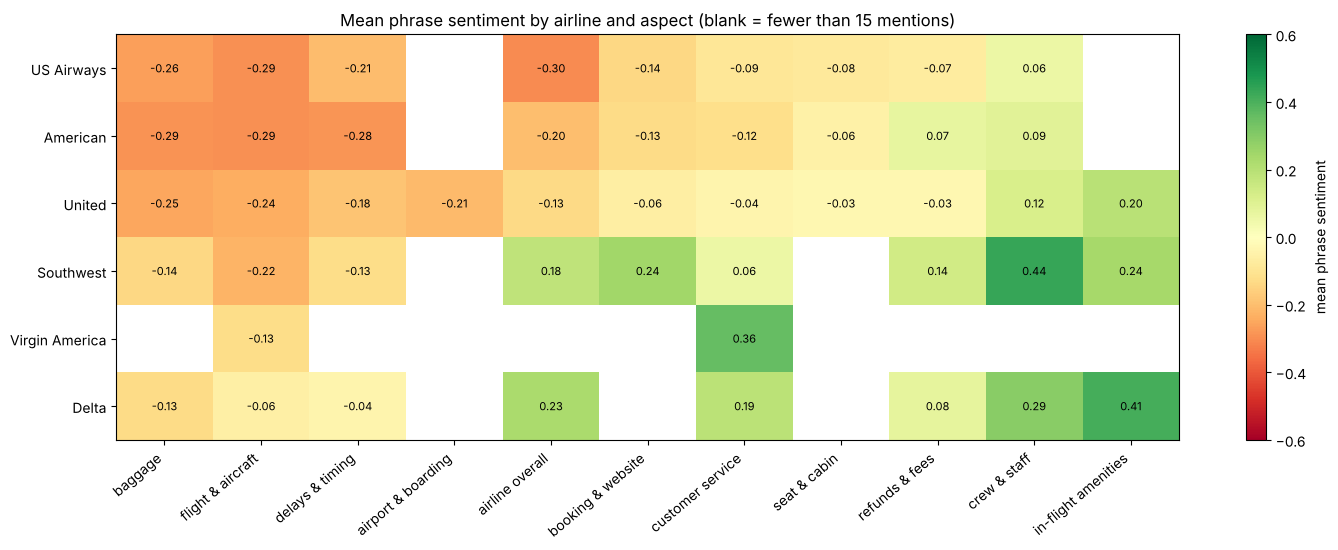

In [16]:
MIN_MENTIONS = 15

g = (op[op["aspect"] != "other"]
       .groupby(["airline", "aspect"])["phrase_score"]
       .agg(["mean", "size"]).reset_index())
g.loc[g["size"] < MIN_MENTIONS, "mean"] = np.nan
heat = g.pivot(index="airline", columns="aspect", values="mean")
heat = heat[agg.index.intersection(heat.columns)]            # same aspect order as 8.1
heat = heat.loc[heat.mean(axis=1).sort_values().index]       # most negative airline at the top

fig, ax = plt.subplots(figsize=(1.15 * heat.shape[1] + 2, 0.6 * heat.shape[0] + 2))
im = ax.imshow(heat.values, cmap="RdYlGn", vmin=-0.6, vmax=0.6, aspect="auto")
ax.set_xticks(range(heat.shape[1]), heat.columns, rotation=40, ha="right")
ax.set_yticks(range(heat.shape[0]), heat.index)
for r in range(heat.shape[0]):
    for c in range(heat.shape[1]):
        v = heat.values[r, c]
        if not np.isnan(v):
            ax.text(c, r, f"{v:.2f}", ha="center", va="center", fontsize=8)
ax.set_title(f"Mean phrase sentiment by airline and aspect (blank = fewer than {MIN_MENTIONS} mentions)")
fig.colorbar(im, ax=ax, label="mean phrase sentiment")
plt.tight_layout()
plt.show()

### 8.3 Most frequent keywords and phrases

Noun-phrase keywords across all tweets, and then separately for tweets humans labelled negative and positive. The contrast shows what customers complain about versus what they praise.

In [17]:
def top_keywords(mask, n=12):
    c = Counter()
    for kws in tw.loc[mask, "keywords"]:
        c.update(kws)
    return c.most_common(n)

all_kw = pd.DataFrame(top_keywords(tw["human_label"].notna()), columns=["phrase", "count"])
neg_kw = pd.DataFrame(top_keywords(tw["human_label"] == "negative"), columns=["negative tweets", "n"])
pos_kw = pd.DataFrame(top_keywords(tw["human_label"] == "positive"), columns=["positive tweets", "n "])
pd.concat([all_kw, neg_kw, pos_kw], axis=1)

,phrase,count,negative tweets,n,positive tweets,n
0,flight,2212,flight,1642,thank,394
1,thank,738,hold,508,flight,172
2,plane,557,plane,472,guy,83
3,bag,525,bag,469,🙏,73
4,hold,520,hour,312,help,55
5,time,400,time,304,time,47
6,guy,326,phone,260,airline,39
7,hour,322,thank,228,plane,35
8,phone,296,gate,221,crew,34
9,airline,277,airline,215,way,28


### 8.4 Why syntax helps: phrase-level vs. tweet-level sentiment

A tweet can mix opinions ("great crew but awful delays"), and a whole-tweet score averages them away. Here are tweets where the syntactic rules found both positive and negative phrases.

In [18]:
mixed = op.groupby("tweet")["phrase_label"].nunique()
mixed_ids = mixed[mixed > 1].index
print(f"Tweets with both positive and negative opinionated phrases: {len(mixed_ids)} "
      f"({len(mixed_ids) / (tw['n_opinionated'] > 0).sum():.1%} of tweets with any opinionated phrase)")

for i in pd.Series(mixed_ids).sample(5, random_state=RANDOM_STATE):
    print(f"\n[{i}] {tweets.loc[i, 'clean_text']}")
    print(f"  human label: {tw.loc[i, 'human_label']} | tweet-level score: {tw.loc[i, 'sentence_score']:+.3f}")
    print(op[op["tweet"] == i][["aspect_raw", "opinion", "phrase_score"]].to_string(index=False))

Tweets with both positive and negative opinionated phrases: 339 (7.2% of tweets with any opinionated phrase)

[11835] new plane, gogo, easy power for laptop, iPhone, just missing a good boat-style swivel cup holder for my dietcoke happyflier
  human label: positive | tweet-level score: +0.557
      aspect_raw opinion  phrase_score
           power    easy         0.440
style cup holder    good         0.440
style cup holder missing        -0.296

[4167] Hi JH, my experience with United has been entirely disgusting but yes, I'd like assistance in getting compensated for my bag.
  human label: negative | tweet-level score: +0.775
aspect_raw    opinion  phrase_score
     hi jh disgusting        -0.527
experience disgusting        -0.527
assistance       like         0.361

[4112] But I got a bad exchange rate so want my money back. Please can you refund without penalty.
  human label: negative | tweet-level score: +0.368
   aspect_raw opinion  phrase_score
exchange rate     bad        -0.

## 9. Evaluation against the human labels

The dataset gives us something the original demo did not have: a human label for every tweet. We turn each method into a tweet-level prediction and compare:

- **Tweet-level VADER:** the compound score of the whole tweet.
- **Phrase-level (syntax + semantics):** the mean score of the opinionated phrases in the tweet. Tweets where no rule fires get no phrase-level prediction, so we report **coverage**.
- **Hybrid:** use the phrase-level label where there is one, otherwise fall back to tweet-level VADER.

Because the phrase-level method only covers some tweets, the fair comparison is on the same subset of tweets, which is why the second and third rows below use the same covered tweets.

In [19]:
tw["sentence_label"] = tw["sentence_score"].map(label)
tw["phrase_label"] = tw["phrase_mean"].map(lambda x: label(x) if pd.notna(x) else np.nan)
tw["hybrid_label"] = tw["phrase_label"].fillna(tw["sentence_label"])

covered = tw["phrase_label"].notna()
human = tw["human_label"]

results = pd.DataFrame([
    ("Tweet-level VADER (all tweets)",             len(tw),        (tw["sentence_label"] == human).mean()),
    ("Phrase-level, covered tweets only",          covered.sum(),  (tw.loc[covered, "phrase_label"] == human[covered]).mean()),
    ("Tweet-level VADER, same covered tweets",     covered.sum(),  (tw.loc[covered, "sentence_label"] == human[covered]).mean()),
    ("Hybrid: phrase-level, else tweet-level",     len(tw),        (tw["hybrid_label"] == human).mean()),
], columns=["method", "tweets", "accuracy"])
results["accuracy"] = results["accuracy"].round(3)
print(f"Coverage of the phrase-level method: {covered.mean():.1%} of tweets")
print(f"Majority-class baseline (always 'negative'): {(human == 'negative').mean():.3f}")
results

Coverage of the phrase-level method: 32.7% of tweets
Majority-class baseline (always 'negative'): 0.635


,method,tweets,accuracy
0,Tweet-level VADER (all tweets),14294,0.570
1,"Phrase-level, covered tweets only",4678,0.682
2,"Tweet-level VADER, same covered tweets",4678,0.676
3,"Hybrid: phrase-level, else tweet-level",14294,0.573


In [20]:
order = ["negative", "neutral", "positive"]
print("Phrase-level prediction vs human label (covered tweets), row-normalised:")
display(pd.crosstab(human[covered], tw.loc[covered, "phrase_label"], normalize="index").reindex(index=order, columns=order).round(2))
print("Tweet-level VADER vs human label (same covered tweets), row-normalised:")
display(pd.crosstab(human[covered], tw.loc[covered, "sentence_label"], normalize="index").reindex(index=order, columns=order).round(2))

Phrase-level prediction vs human label (covered tweets), row-normalised:


phrase_label,negative,neutral,positive
human_label,,,
negative,0.72,0.02,0.26
neutral,0.35,0.01,0.64
positive,0.08,0.01,0.90


Tweet-level VADER vs human label (same covered tweets), row-normalised:


sentence_label,negative,neutral,positive
human_label,,,
negative,0.70,0.03,0.27
neutral,0.32,0.02,0.66
positive,0.04,0.01,0.95


### 9.1 Do the extracted aspects match the human-labelled complaint reasons?

For negative tweets the dataset also records *why* the customer was unhappy. We map each reason to the aspect group we would expect, then check how often the pipeline found a **negative phrase about that aspect** in those tweets. This tests the aspect grouping rather than the sentiment.

In [21]:
REASON_TO_ASPECT = {
    "Lost Luggage": "baggage",
    "Damaged Luggage": "baggage",
    "Customer Service Issue": "customer service",
    "Late Flight": "delays & timing",
    "Cancelled Flight": "flight & aircraft",
    "Flight Booking Problems": "booking & website",
    "Flight Attendant Complaints": "crew & staff",
    "longlines": "airport & boarding",
}

neg_pairs = op[op["phrase_label"] == "negative"]
neg_aspects_by_tweet = neg_pairs.groupby("tweet")["aspect"].apply(set)

rows = []
for reason, aspect in REASON_TO_ASPECT.items():
    ids = tw.index[(tw["human_label"] == "negative") & (tw["negativereason"] == reason)]
    any_neg = [i for i in ids if i in neg_aspects_by_tweet.index]
    hit = [i for i in any_neg if aspect in neg_aspects_by_tweet[i]]
    rows.append({
        "complaint reason": reason, "expected aspect": aspect, "tweets": len(ids),
        "any negative phrase": round(len(any_neg) / max(len(ids), 1), 3),
        "negative phrase on expected aspect": round(len(hit) / max(len(ids), 1), 3),
    })
pd.DataFrame(rows).sort_values("tweets", ascending=False)

,complaint reason,expected aspect,tweets,any negative phrase,negative phrase on expected aspect
2,Customer Service Issue,customer service,2880,0.253,0.095
3,Late Flight,delays & timing,1649,0.306,0.037
4,Cancelled Flight,flight & aircraft,829,0.438,0.314
0,Lost Luggage,baggage,719,0.289,0.153
5,Flight Booking Problems,booking & website,522,0.193,0.025
6,Flight Attendant Complaints,crew & staff,475,0.333,0.080
7,longlines,airport & boarding,177,0.232,0.006
1,Damaged Luggage,baggage,73,0.356,0.137


## 10. Checking negation handling

The `neg` dependency is what makes *not friendly* come out negative and *not bad* come out positive. Checking those cases directly:

In [22]:
tests = ["The crew is friendly.", "The crew is not friendly.", "The service is bad.", "The service is not bad.",
         "The flight was not late.", "I really love the new seats."]
for t in tests:
    out = [(p["aspect"], ("not " if p["negated"] else "") + p["opinion"],
            round(opinion_score(p["opinion"], p["negated"], p["boost"]), 2))
           for p in extract_pairs(nlp(t))]
    print(f"{t:32s} -> {out}")

The crew is friendly.            -> [('crew', 'friendly', 0.49)]
The crew is not friendly.        -> [('crew', 'not friendly', -0.37)]
The service is bad.              -> [('service', 'bad', -0.54)]
The service is not bad.          -> [('service', 'not bad', 0.41)]
The flight was not late.         -> [('flight', 'not late', 0.22)]
I really love the new seats.     -> [('seat', 'new', 0.0), ('seat', 'love', 0.83)]


## 11. Discussion

**What worked**

- The dependency rules attached opinions to the right aspect, and the `neg` relation flipped polarity correctly (*not friendly* is negative, *not bad* is positive; see section 10).
- The pipeline turns thousands of tweets into a feature-level view. Baggage (mean about -0.24), flight and aircraft (-0.24) and delays (-0.18) are the most negative aspects. Crew and staff (+0.20) and in-flight amenities (+0.23) are the most positive. Customer service sits near zero (-0.03) because it attracts both thanks and complaints.
- Where a tweet mixes opinions (339 tweets, about 7% of those with any opinionated phrase), the phrase-level view keeps both sides. For example, *appreciate the response* and *frustrating* in the same tweet are separated rather than averaged away.

**What the evaluation showed (honest results)**

- **Coverage is the main weakness.** The four rules found at least one opinionated phrase in only 32.7% of tweets (4,678 of 14,294). Most tweets are short complaints with no explicit adjective on a noun.
- **Accuracy gain is small.** On the tweets the rules cover, phrase-level sentiment matched the human label 68.2% of the time against 67.6% for tweet-level VADER on the same tweets. On all tweets, tweet-level VADER reached 57.0%, which is below the 63.5% you get by always guessing *negative*, and the hybrid reached 57.3%. So in this dataset the benefit of syntax is **attribution** (which aspect, which airline) rather than a large jump in overall accuracy.
- **Neutral tweets are almost never predicted.** Both methods label most human-neutral tweets as positive or negative, because polite wording such as *thanks* or *please* carries positive lexicon scores.
- **Aspect check (section 9.1).** Only 31% of *Cancelled Flight* tweets and 15% of *Lost Luggage* tweets contained a negative phrase on the matching aspect, and *Late Flight*, *Flight Booking Problems* and *longlines* were below 4%. Many complaints are implicit (*stuck on hold for two hours*, *my bag never arrived*), so no opinion word is attached to the aspect.

**Limitations we noticed**

- **Sarcasm and politeness.** *Thanks for nothing* or *great, another delay* contain positive words that VADER scores as positive. Syntax alone cannot detect irony.
- **Rule coverage.** We handle four patterns. Passive voice is missed (*the flight was delayed*, *my bag was lost* produce no pair). In a quick test on a 2,500-tweet sample, adding a `nsubjpass` + verb rule raised coverage from about 33% to 36%. Comparatives and implicit opinions are also missed.
- **Verb opinions.** The verb + object rule treats verbs such as *want*, *like* or *miss* as opinions. In complaints these are often positive-sounding verbs in a negative situation (*want my money back*).
- **Lexicon sentiment.** VADER is a general-purpose lexicon. We added a dozen airline terms, but other domain words and slang are still scored wrongly or not at all.
- **Hand-built aspect map.** Roughly 41% of opinionated phrases fall into `other` (*experience*, *day*, *job*, *thing*). The map is easy to inspect but will need extending for other domains.

**Possible extensions**

- Add rules for passives, comparatives and clause-level contrast (*but*).
- Replace the lexicon with a pretrained sentiment model (for example a transformer from Hugging Face) while still using dependency parsing to decide *which phrase* to score.
- Use the human `negativereason` labels to learn the aspect map instead of writing it by hand.
- Handle implicit complaints by treating certain event nouns (*delay*, *cancellation*, *lost bag*) as negative on their own.

## 12. Conclusion

Syntactic analysis told us *where to look* (which words relate to which aspect), and semantic analysis told us *how to feel about it* (the polarity of those words). Together they gave an aspect-level and airline-level picture of customer sentiment that a whole-tweet score cannot give. Measured against the human labels, the combination was slightly more accurate than tweet-level VADER where it applied, but it applied to only about a third of the tweets, and the clearest next steps are wider rule coverage and a domain-aware sentiment model.

*Prepared by Steve and Spencer.*
